In [1]:
!pip install -q django scikit-fuzzy numpy scipy networkx matplotlib

In [2]:
!django-admin startproject vehicle_diag .
!python manage.py startapp diagnostics
!mkdir -p diagnostics/templates/diagnostics
!mkdir -p diagnostics/static/diagnostics/css diagnostics/static/diagnostics/js

In [3]:
%%writefile vehicle_diag/settings.py
from pathlib import Path

BASE_DIR = Path(__file__).resolve().parent.parent
SECRET_KEY = 'django-insecure-lab6-secret-key'
DEBUG = True

ALLOWED_HOSTS = ['*']
CSRF_TRUSTED_ORIGINS = ['https://*.colab.googleusercontent.com', 'https://*.google.com']

INSTALLED_APPS = [
    'django.contrib.admin',
    'django.contrib.auth',
    'django.contrib.contenttypes',
    'django.contrib.sessions',
    'django.contrib.messages',
    'django.contrib.staticfiles',
    'diagnostics',
]

MIDDLEWARE = [
    'django.middleware.security.SecurityMiddleware',
    'django.contrib.sessions.middleware.SessionMiddleware',
    'django.middleware.common.CommonMiddleware',
    'django.middleware.csrf.CsrfViewMiddleware',
    'django.contrib.auth.middleware.AuthenticationMiddleware',
    'django.contrib.messages.middleware.MessageMiddleware',
    'django.middleware.clickjacking.XFrameOptionsMiddleware',
]

ROOT_URLCONF = 'vehicle_diag.urls'

TEMPLATES = [
    {
        'BACKEND': 'django.template.backends.django.DjangoTemplates',
        'DIRS': [],
        'APP_DIRS': True,
        'OPTIONS': {
            'context_processors': [
                'django.template.context_processors.request',
                'django.contrib.auth.context_processors.auth',
                'django.contrib.messages.context_processors.messages',
            ],
        },
    },
]

WSGI_APPLICATION = 'vehicle_diag.wsgi.application'

DATABASES = {
    'default': {
        'ENGINE': 'django.db.backends.sqlite3',
        'NAME': BASE_DIR / 'db.sqlite3',
    }
}

LANGUAGE_CODE = 'uk'
TIME_ZONE = 'Europe/Kyiv'
USE_I18N = True
USE_TZ = True

STATIC_URL = 'static/'
DEFAULT_AUTO_FIELD = 'django.db.models.BigAutoField'

Overwriting vehicle_diag/settings.py


In [4]:
%%writefile vehicle_diag/urls.py
from django.contrib import admin
from django.urls import include, path

urlpatterns = [
    path('admin/', admin.site.urls),
    path('', include('diagnostics.urls')),
]

Overwriting vehicle_diag/urls.py


In [5]:
%%writefile diagnostics/fuzzy_engine.py
from dataclasses import dataclass
import numpy as np
import skfuzzy as fuzz

INPUT_VARIABLES = {
    'temperature': {
        'label': 'Температура охолоджувальної рідини',
        'unit': '°C',
        'range': (60.0, 130.0),
        'default': 90.0,
        'terms': {
            'low': ('Знижена', 'trap', (60, 60, 70, 82)),
            'normal': ('Нормальна', 'tri', (78, 90, 102)),
            'high': ('Підвищена', 'trap', (98, 110, 130, 130)),
        },
    },
    'oil_pressure': {
        'label': 'Тиск моторного мастила',
        'unit': 'бар',
        'range': (0.0, 6.0),
        'default': 3.0,
        'terms': {
            'low': ('Низький', 'trap', (0, 0, 1.0, 2.0)),
            'normal': ('Нормальний', 'tri', (1.5, 3.0, 4.5)),
            'high': ('Високий', 'trap', (4.0, 5.0, 6.0, 6.0)),
        },
    },
    'vibration': {
        'label': 'Рівень вібрації двигуна',
        'unit': 'мм/с',
        'range': (0.0, 12.0),
        'default': 2.0,
        'terms': {
            'low': ('Низький', 'trap', (0, 0, 2.5, 4.5)),
            'medium': ('Середній', 'tri', (3.5, 6.0, 8.5)),
            'high': ('Високий', 'trap', (7.5, 9.5, 12.0, 12.0)),
        },
    },
    'service_km': {
        'label': 'Пробіг після останнього обслуговування',
        'unit': 'тис. км',
        'range': (0.0, 20.0),
        'default': 5.0,
        'terms': {
            'low': ('Малий', 'trap', (0, 0, 5, 9)),
            'medium': ('Середній', 'tri', (7, 11, 15)),
            'overdue': ('Прострочений', 'trap', (13, 16, 20, 20)),
        },
    },
}

OUTPUT_RANGE = (0.0, 100.0)
RISK_TERMS = {
    'low': ('Низький', 'trap', (0, 0, 15, 30)),
    'medium': ('Середній', 'tri', (25, 45, 65)),
    'high': ('Високий', 'tri', (50, 68, 85)),
    'critical': ('Критичний', 'trap', (72, 90, 100, 100)),
}

SUGENO_CONSTANTS = {'low': 10.0, 'medium': 40.0, 'high': 70.0, 'critical': 95.0}
DEFUZZ_METHODS = ('centroid', 'bisector', 'mom', 'som', 'lom')

UNIVERSES = {
    name: np.linspace(var['range'][0], var['range'][1], 601)
    for name, var in INPUT_VARIABLES.items()
}
RISK_UNIVERSE = np.linspace(OUTPUT_RANGE[0], OUTPUT_RANGE[1], 601)

def build_mf(kind, params, universe):
    if kind == 'tri':
        return fuzz.trimf(universe, params)
    if kind == 'trap':
        return fuzz.trapmf(universe, params)
    raise ValueError(f'Невідомий тип функції належності {kind}')

INPUT_MFS = {
    var_name: {
        term: build_mf(kind, params, UNIVERSES[var_name])
        for term, (_, kind, params) in var['terms'].items()
    }
    for var_name, var in INPUT_VARIABLES.items()
}

RISK_MFS = {
    term: build_mf(kind, params, RISK_UNIVERSE)
    for term, (_, kind, params) in RISK_TERMS.items()
}

@dataclass(frozen=True)
class Rule:
    code: str
    conditions: tuple
    output: str
    operator: str = 'and'
    weight: float = 1.0
    cause: str = ''
    advice: str = ''

RULES = [
    Rule('R1', (('oil_pressure', 'low'), ('temperature', 'high')), 'critical',
         cause='Перегрів у поєднанні з падінням тиску мастила, ймовірне масляне голодування.',
         advice='Негайно зупинити двигун і перевірити рівень мастила та масляний насос.'),
    Rule('R2', (('oil_pressure', 'low'), ('vibration', 'high')), 'critical',
         cause='Критичний знос підшипників або дефіцит змащення при високому навантаженні.',
         advice='Припинити експлуатацію та провести діагностику кривошипно-шатунного механізму.'),
    Rule('R3', (('temperature', 'high'), ('vibration', 'high')), 'critical',
         cause='Термічна деформація або детонація при перегріві двигуна.',
         advice='Зупинити двигун, дати охолонути та перевірити систему охолодження й запалювання.'),
    Rule('R4', (('oil_pressure', 'low'),), 'high', weight=0.6,
         cause='Недостатній тиск мастила, засмічений фільтр або знос насоса.',
         advice='Замінити масляний фільтр і виміряти тиск контрольним манометром.'),
    Rule('R5', (('temperature', 'high'),), 'high', weight=0.6,
         cause='Порушення циркуляції охолоджувальної рідини або несправність термостата.',
         advice='Перевірити рівень антифризу, радіатор і роботу вентилятора охолодження.'),
    Rule('R6', (('vibration', 'high'),), 'high', weight=0.6,
         cause='Дисбаланс обертових елементів або пошкодження опор двигуна.',
         advice='Оглянути подушки двигуна та перевірити роботу циліндрів.'),
    Rule('R7', (('service_km', 'overdue'), ('vibration', 'medium')), 'medium',
         cause='Старіння моторного мастила та знос розхідників через перевищення інтервалу ТО.',
         advice='Провести планове технічне обслуговування із заміною мастила та фільтрів.'),
    Rule('R8', (('service_km', 'overdue'),), 'medium', weight=0.5,
         cause='Перевищено рекомендований пробіг між сервісними обслуговуваннями.',
         advice='Запланувати візит на СТО для проведення регламентних робіт.'),
    Rule('R9', (('vibration', 'medium'),), 'medium', weight=0.8,
         cause='Підвищена вібрація внаслідок нерівномірної роботи паливної апаратури або свічок.',
         advice='Виконати комп’ютерну діагностику запалювання та паливної системи.'),
    Rule('R10', (('oil_pressure', 'high'),), 'medium', weight=0.8,
         cause='Надлишковий тиск через заклинювання редукційного клапана або надто густе мастило.',
         advice='Перевірити редукційний клапан масляного насоса.'),
    Rule('R11', (('temperature', 'normal'), ('oil_pressure', 'normal'), ('vibration', 'low')), 'low',
         cause='Параметри відповідають нормі.',
         advice='Додаткових дій не потрібно.'),
    Rule('R12', (('temperature', 'low'), ('oil_pressure', 'normal'), ('vibration', 'low')), 'low',
         cause='Двигун працює в режимі прогріву, відхилень не виявлено.',
         advice='Дочекатися виходу двигуна на робочу температуру.'),
    Rule('R13', (('service_km', 'low'), ('vibration', 'low'), ('oil_pressure', 'normal')), 'low',
         cause='Нещодавно виконано ТО, основні вузли справні.',
         advice='Продовжувати штатну експлуатацію.'),
    Rule('R14', (('service_km', 'medium'), ('vibration', 'low'), ('temperature', 'normal')), 'low', weight=0.9,
         cause='Показники в межах допустимих норм.',
         advice='Контролювати рівень технічних рідин у штатному режимі.'),
]

def fuzzify(values):
    degrees = {}
    for var_name, var in INPUT_VARIABLES.items():
        x = float(values[var_name])
        degrees[var_name] = {
            term: float(fuzz.interp_membership(UNIVERSES[var_name], INPUT_MFS[var_name][term], x))
            for term in var['terms']
        }
    return degrees

def _and(values, tnorm):
    return min(values) if tnorm == 'min' else float(np.prod(values))

def _or(values, tnorm):
    if tnorm == 'min':
        return max(values)
    result = 0.0
    for v in values:
        result = result + v - result * v
    return result

def activate_rules(degrees, tnorm='min'):
    strengths = []
    for rule in RULES:
        mus = [degrees[var][term] for var, term in rule.conditions]
        raw = _and(mus, tnorm) if rule.operator == 'and' else _or(mus, tnorm)
        strengths.append((rule, raw * rule.weight))
    return strengths

def mamdani_aggregate(strengths, tnorm='min'):
    aggregated = np.zeros_like(RISK_UNIVERSE)
    clipped = []
    for rule, alpha in strengths:
        mf = RISK_MFS[rule.output]
        shaped = np.fmin(alpha, mf) if tnorm == 'min' else alpha * mf
        clipped.append((rule, shaped))
        aggregated = np.fmax(aggregated, shaped)
    return aggregated, clipped

def infer_mamdani(strengths, tnorm='min', method='centroid'):
    aggregated, _ = mamdani_aggregate(strengths, tnorm)
    if aggregated.sum() == 0:
        return None
    return float(fuzz.defuzz(RISK_UNIVERSE, aggregated, method))

def infer_sugeno(strengths):
    total = sum(alpha for _, alpha in strengths)
    if total == 0:
        return None
    weighted = sum(alpha * SUGENO_CONSTANTS[rule.output] for rule, alpha in strengths)
    return float(weighted / total)

LEVELS = (
    (25, 'ok', 'Справний стан'),
    (50, 'attention', 'Потребує уваги'),
    (70, 'warning', 'Високий ризик відмови'),
    (101, 'critical', 'Критичний стан, експлуатація небезпечна'),
)

def classify(risk):
    for upper, code, title in LEVELS:
        if risk < upper:
            return {'code': code, 'title': title}

def rule_text(rule):
    parts = [f"{INPUT_VARIABLES[v]['label'].lower()} — {INPUT_VARIABLES[v]['terms'][t][0].lower()}" for v, t in rule.conditions]
    joiner = ' І ' if rule.operator == 'and' else ' АБО '
    return f"Якщо {joiner.join(parts)}, то ризик {RISK_TERMS[rule.output][0].lower()}"

COMPARISON_SET = [
    ('mamdani', 'min', 'centroid', 'Мамдані (min, центр ваги)'),
    ('mamdani', 'min', 'bisector', 'Мамдані (min, бісектриса)'),
    ('mamdani', 'min', 'mom', 'Мамдані (min, середнє максимумів)'),
    ('mamdani', 'prod', 'centroid', 'Мамдані (prod, центр ваги)'),
    ('sugeno', 'min', 'centroid', 'Сугено (min)'),
    ('sugeno', 'prod', 'centroid', 'Сугено (prod)'),
]

def run_algorithm(degrees, algorithm, tnorm, method):
    strengths = activate_rules(degrees, tnorm)
    return infer_mamdani(strengths, tnorm, method) if algorithm == 'mamdani' else infer_sugeno(strengths)

def diagnose(values, algorithm='mamdani', tnorm='min', method='centroid'):
    degrees = fuzzify(values)
    strengths = activate_rules(degrees, tnorm)
    risk = infer_mamdani(strengths, tnorm, method) if algorithm == 'mamdani' else infer_sugeno(strengths)
    if risk is None:
        return {'covered': False}

    fired = [
        {
            'code': rule.code,
            'text': rule_text(rule),
            'alpha': round(alpha, 3),
            'cause': rule.cause,
            'advice': rule.advice,
        }
        for rule, alpha in sorted(strengths, key=lambda item: -item[1])
        if alpha > 0.01
    ]

    comparison = []
    for alg, tn, meth, title in COMPARISON_SET:
        value = run_algorithm(degrees, alg, tn, meth)
        comparison.append({'title': title, 'risk': None if value is None else round(value, 2)})

    return {
        'covered': True,
        'risk': round(risk, 2),
        'level': classify(risk),
        'degrees': {v: {t: round(d, 3) for t, d in terms.items()} for v, terms in degrees.items()},
        'fired': fired,
        'comparison': comparison,
    }

Writing diagnostics/fuzzy_engine.py


In [6]:
%%writefile diagnostics/models.py
from django.db import models

class DiagnosticRecord(models.Model):
    ALGORITHMS = [('mamdani', 'Мамдані'), ('sugeno', 'Сугено')]
    vehicle = models.CharField('Транспортний засіб', max_length=80)
    temperature = models.FloatField('Температура, °C')
    oil_pressure = models.FloatField('Тиск мастила, бар')
    vibration = models.FloatField('Вібрація, мм/с')
    service_km = models.FloatField('Пробіг після ТО, тис. км')
    algorithm = models.CharField('Алгоритм', max_length=10, choices=ALGORITHMS)
    risk = models.FloatField('Ризик відмови, %')
    level = models.CharField('Висновок', max_length=80)
    created_at = models.DateTimeField('Дата діагностики', auto_now_add=True)

    class Meta:
        ordering = ['-created_at']
        verbose_name = 'результат діагностики'
        verbose_name_plural = 'результати діагностики'

    def __str__(self):
        return f'{self.vehicle} ({self.risk:.1f} %)'

Overwriting diagnostics/models.py


In [7]:
%%writefile diagnostics/admin.py
from django.contrib import admin
from .models import DiagnosticRecord

@admin.register(DiagnosticRecord)
class DiagnosticRecordAdmin(admin.ModelAdmin):
    list_display = ('vehicle', 'algorithm', 'risk', 'level', 'created_at')
    list_filter = ('algorithm', 'level')
    search_fields = ('vehicle',)

Overwriting diagnostics/admin.py


In [8]:
%%writefile diagnostics/forms.py
from django import forms
from . import fuzzy_engine as fe

class DiagnosticForm(forms.Form):
    vehicle = forms.CharField(label='Транспортний засіб', max_length=80, required=False, initial='Тестовий автомобіль')
    algorithm = forms.ChoiceField(label='Алгоритм виводу', choices=[('mamdani', 'Мамдані'), ('sugeno', 'Сугено')])
    tnorm = forms.ChoiceField(label='Операція І', choices=[('min', 'Мінімум'), ('prod', 'Алгебраїчний добуток')])
    defuzz = forms.ChoiceField(
        label='Метод дефазифікації',
        choices=[
            ('centroid', 'Центр ваги'),
            ('bisector', 'Бісектриса'),
            ('mom', 'Середнє максимумів'),
            ('som', 'Найменший максимум'),
            ('lom', 'Найбільший максимум'),
        ]
    )

    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        for name, var in fe.INPUT_VARIABLES.items():
            low, high = var['range']
            self.fields[name] = forms.FloatField(
                label=f"{var['label']}, {var['unit']}",
                min_value=low, max_value=high, initial=var['default']
            )

Writing diagnostics/forms.py


In [9]:
%%writefile diagnostics/views.py
import json
from django.http import JsonResponse
from django.shortcuts import redirect, render
from django.views.decorators.http import require_POST
from . import fuzzy_engine as fe
from .forms import DiagnosticForm
from .models import DiagnosticRecord

def _run(cleaned):
    values = {name: cleaned[name] for name in fe.INPUT_VARIABLES}
    return fe.diagnose(values, cleaned['algorithm'], cleaned['tnorm'], cleaned['defuzz'])

def index(request):
    form = DiagnosticForm()
    variables = [
        {'field': form[name], 'unit': var['unit'], 'low': var['range'][0], 'high': var['range'][1]}
        for name, var in fe.INPUT_VARIABLES.items()
    ]
    initial_result = _run({
        'algorithm': 'mamdani', 'tnorm': 'min', 'defuzz': 'centroid',
        **{name: var['default'] for name, var in fe.INPUT_VARIABLES.items()}
    })
    return render(request, 'diagnostics/index.html', {
        'form': form, 'variables': variables, 'result': initial_result
    })

@require_POST
def api_diagnose(request):
    try:
        payload = json.loads(request.body)
    except json.JSONDecodeError:
        return JsonResponse({'errors': {'__all__': ['Некоректний JSON']}}, status=400)
    form = DiagnosticForm(payload)
    if not form.is_valid():
        return JsonResponse({'errors': form.errors.get_json_data()}, status=400)
    return JsonResponse(_run(form.cleaned_data))

@require_POST
def save_record(request):
    form = DiagnosticForm(request.POST)
    if not form.is_valid():
        return redirect('diagnostics:index')
    result = _run(form.cleaned_data)
    if result['covered']:
        data = form.cleaned_data
        DiagnosticRecord.objects.create(
            vehicle=data['vehicle'] or 'Без назви',
            temperature=data['temperature'], oil_pressure=data['oil_pressure'],
            vibration=data['vibration'], service_km=data['service_km'],
            algorithm=data['algorithm'], risk=result['risk'],
            level=result['level']['title']
        )
    return redirect('diagnostics:history')

def history(request):
    records = DiagnosticRecord.objects.all()[:20]
    return render(request, 'diagnostics/history.html', {'records': records})

Overwriting diagnostics/views.py


In [10]:
%%writefile diagnostics/templates/diagnostics/base.html
<!DOCTYPE html>
<html lang="uk">
<head>
    <meta charset="UTF-8">
    <title>Експертна система діагностики ТЗ</title>
    <style>
        body { font-family: Arial, sans-serif; margin: 0; background: #f4f6f9; color: #222; }
        header { background: #1e293b; color: #fff; padding: 14px 24px; display: flex; justify-content: space-between; align-items: center; }
        header a { color: #93c5fd; text-decoration: none; margin-left: 16px; font-weight: bold; }
        .container { max-width: 1150px; margin: 24px auto; padding: 0 16px; }
        .grid { display: grid; grid-template-columns: 1fr 1.2fr; gap: 20px; }
        .card { background: #fff; padding: 20px; border-radius: 8px; box-shadow: 0 2px 6px rgba(0,0,0,0.08); }
        .field { margin-bottom: 14px; }
        label { display: block; font-weight: bold; margin-bottom: 4px; font-size: 14px; }
        input[type="number"], input[type="text"], select { width: 100%; padding: 7px; border: 1px solid #cbd5e1; border-radius: 4px; box-sizing: border-box; }
        input[type="range"] { width: 100%; margin-top: 4px; }
        button { background: #2563eb; color: #fff; border: none; padding: 10px 18px; border-radius: 5px; cursor: pointer; font-size: 15px; width: 100%; }
        button:hover { background: #1d4ed8; }
        .risk-box { padding: 14px; border-radius: 6px; margin-bottom: 16px; font-size: 18px; font-weight: bold; text-align: center; }
        .ok { background: #dcfce7; color: #166534; }
        .attention { background: #fef9c3; color: #854d0e; }
        .warning { background: #ffedd5; color: #9a3412; }
        .critical { background: #fee2e2; color: #991b1b; }
        table { width: 100%; border-collapse: collapse; margin-top: 10px; font-size: 14px; }
        th, td { border: 1px solid #e2e8f0; padding: 8px; text-align: left; }
        th { background: #f8fafc; }
        .rule-item { background: #f8fafc; border-left: 4px solid #3b82f6; padding: 8px 12px; margin-bottom: 8px; font-size: 13px; }
    </style>
</head>
<body>
<header>
    <div><strong>Експертна система діагностики двигуна ТЗ</strong></div>
    <nav>
        <a href="{% url 'diagnostics:index' %}">Діагностика</a>
        <a href="{% url 'diagnostics:history' %}">Журнал перевірок</a>
    </nav>
</header>
<div class="container">
    {% block content %}{% endblock %}
</div>
</body>
</html>

Writing diagnostics/templates/diagnostics/base.html


In [11]:
%%writefile diagnostics/templates/diagnostics/index.html
{% extends 'diagnostics/base.html' %}
{% block content %}
<div class="grid">
    <div class="card">
        <h3>Вхідні параметри та налаштування</h3>
        <form id="diag-form" method="post" action="{% url 'diagnostics:save' %}" data-api-url="{% url 'diagnostics:api' %}">
            {% csrf_token %}
            <div class="field">{{ form.vehicle.label_tag }}{{ form.vehicle }}</div>
            <div class="field">{{ form.algorithm.label_tag }}{{ form.algorithm }}</div>
            <div class="field">{{ form.tnorm.label_tag }}{{ form.tnorm }}</div>
            <div class="field">{{ form.defuzz.label_tag }}{{ form.defuzz }}</div>
            <hr>
            {% for v in variables %}
            <div class="field">
                {{ v.field.label_tag }}
                {{ v.field }}
                <input type="range" step="0.1" min="{{ v.low }}" max="{{ v.high }}" value="{{ v.field.value }}" data-sync="{{ v.field.name }}">
            </div>
            {% endfor %}
            <button type="submit">Зберегти результат у журнал</button>
        </form>
    </div>

    <div class="card">
        <h3>Результат нечіткого виводу</h3>
        <div id="risk-banner" class="risk-box {{ result.level.code }}">
            Ризик відмови: <span id="risk-val">{{ result.risk }}</span>% — <span id="risk-title">{{ result.level.title }}</span>
        </div>

        <h4>Спрацювали правила (пояснення висновку):</h4>
        <div id="fired-rules">
            {% for r in result.fired %}
            <div class="rule-item">
                <strong>[{{ r.code }}] (сила: {{ r.alpha }})</strong>: {{ r.text }}<br>
                <em>Причина:</em> {{ r.cause }}<br>
                <em>Рекомендація:</em> {{ r.advice }}
            </div>
            {% endfor %}
        </div>

        <h4>Порівняння алгоритмів та методів дефазифікації:</h4>
        <table>
            <thead><tr><th>Метод виводу</th><th>Ризик, %</th></tr></thead>
            <tbody id="comp-body">
                {% for c in result.comparison %}
                <tr><td>{{ c.title }}</td><td>{{ c.risk }}%</td></tr>
                {% endfor %}
            </tbody>
        </table>
    </div>
</div>

<script>
const form = document.getElementById('diag-form');
const apiUrl = form.dataset.apiUrl;
const csrfToken = form.querySelector('[name=csrfmiddlewaretoken]').value;

document.querySelectorAll('input[type="range"]').forEach(slider => {
    const numInput = form.querySelector(`[name="${slider.dataset.sync}"]`);
    slider.addEventListener('input', () => { numInput.value = slider.value; updateDiagnose(); });
    numInput.addEventListener('input', () => { slider.value = numInput.value; updateDiagnose(); });
});

form.querySelectorAll('select').forEach(sel => sel.addEventListener('change', updateDiagnose));

async function updateDiagnose() {
    const data = {};
    new FormData(form).forEach((v, k) => { if (k !== 'csrfmiddlewaretoken') data[k] = v; });
    const res = await fetch(apiUrl, {
        method: 'POST',
        headers: { 'Content-Type': 'application/json', 'X-CSRFToken': csrfToken },
        body: JSON.stringify(data)
    });
    if (!res.ok) return;
    const json = await res.json();
    if (!json.covered) return;

    const banner = document.getElementById('risk-banner');
    banner.className = 'risk-box ' + json.level.code;
    document.getElementById('risk-val').textContent = json.risk;
    document.getElementById('risk-title').textContent = json.level.title;

    document.getElementById('fired-rules').innerHTML = json.fired.map(r => `
        <div class="rule-item">
            <strong>[${r.code}] (сила: ${r.alpha})</strong>: ${r.text}<br>
            <em>Причина:</em> ${r.cause}<br>
            <em>Рекомендація:</em> ${r.advice}
        </div>
    `).join('');

    document.getElementById('comp-body').innerHTML = json.comparison.map(c => `
        <tr><td>${c.title}</td><td>${c.risk}%</td></tr>
    `).join('');
}
</script>
{% endblock %}

Writing diagnostics/templates/diagnostics/index.html


In [12]:
%%writefile diagnostics/templates/diagnostics/history.html
{% extends 'diagnostics/base.html' %}
{% block content %}
<div class="card">
    <h3>Журнал збережених результатів діагностики</h3>
    <table>
        <thead>
            <tr>
                <th>Дата</th><th>ТЗ</th><th>Темп., °C</th><th>Тиск, бар</th>
                <th>Вібрація</th><th>Пробіг</th><th>Алгоритм</th><th>Ризик</th><th>Висновок</th>
            </tr>
        </thead>
        <tbody>
            {% for r in records %}
            <tr>
                <td>{{ r.created_at|date:"d.m.Y H:i" }}</td><td>{{ r.vehicle }}</td>
                <td>{{ r.temperature }}</td><td>{{ r.oil_pressure }}</td>
                <td>{{ r.vibration }}</td><td>{{ r.service_km }}</td>
                <td>{{ r.get_algorithm_display }}</td><td><strong>{{ r.risk }}%</strong></td><td>{{ r.level }}</td>
            </tr>
            {% empty %}
            <tr><td colspan="9">Записів поки немає.</td></tr>
            {% endfor %}
        </tbody>
    </table>
</div>
{% endblock %}

Writing diagnostics/templates/diagnostics/history.html


In [13]:
%%writefile diagnostics/tests.py
from django.test import TestCase
from django.urls import reverse
from . import fuzzy_engine as fe

class FuzzyDiagnosticsTests(TestCase):
    def test_normal_state(self):
        res = fe.diagnose({'temperature': 90, 'oil_pressure': 3.0, 'vibration': 2.0, 'service_km': 5.0})
        self.assertTrue(res['covered'])
        self.assertLess(res['risk'], 25)

    def test_critical_state(self):
        res = fe.diagnose({'temperature': 120, 'oil_pressure': 0.5, 'vibration': 10.0, 'service_km': 18.0})
        self.assertTrue(res['covered'])
        self.assertGreater(res['risk'], 70)

    def test_api_endpoint(self):
        response = self.client.post(
            reverse('diagnostics:api'),
            data='{"temperature": 104, "oil_pressure": 1.4, "vibration": 6.0, "service_km": 13.0, "algorithm": "mamdani", "tnorm": "min", "defuzz": "centroid"}',
            content_type='application/json'
        )
        self.assertEqual(response.status_code, 200)
        self.assertIn('risk', response.json())

Overwriting diagnostics/tests.py


In [15]:
%%writefile diagnostics/urls.py
from django.urls import path
from . import views

app_name = 'diagnostics'

urlpatterns = [
    path('', views.index, name='index'),
    path('api/diagnose/', views.api_diagnose, name='api'),
    path('save/', views.save_record, name='save'),
    path('history/', views.history, name='history'),
]

Writing diagnostics/urls.py


In [16]:
!python manage.py makemigrations diagnostics
!python manage.py migrate
!python manage.py test

Migrations for 'diagnostics':
  diagnostics/migrations/0001_initial.py
    + Create model DiagnosticRecord
Operations to perform:
  Apply all migrations: admin, auth, contenttypes, diagnostics, sessions
Running migrations:
  Applying contenttypes.0001_initial... OK
  Applying auth.0001_initial... OK
  Applying admin.0001_initial... OK
  Applying admin.0002_logentry_remove_auto_add... OK
  Applying admin.0003_logentry_add_action_flag_choices... OK
  Applying contenttypes.0002_remove_content_type_name... OK
  Applying auth.0002_alter_permission_name_max_length... OK
  Applying auth.0003_alter_user_email_max_length... OK
  Applying auth.0004_alter_user_username_opts... OK
  Applying auth.0005_alter_user_last_login_null... OK
  Applying auth.0006_require_contenttypes_0002... OK
  Applying auth.0007_alter_validators_add_error_messages... OK
  Applying auth.0008_alter_user_username_max_length... OK
  Applying auth.0009_alter_user_last_name_max_length... OK
  Applying auth.0010_alter_group_na

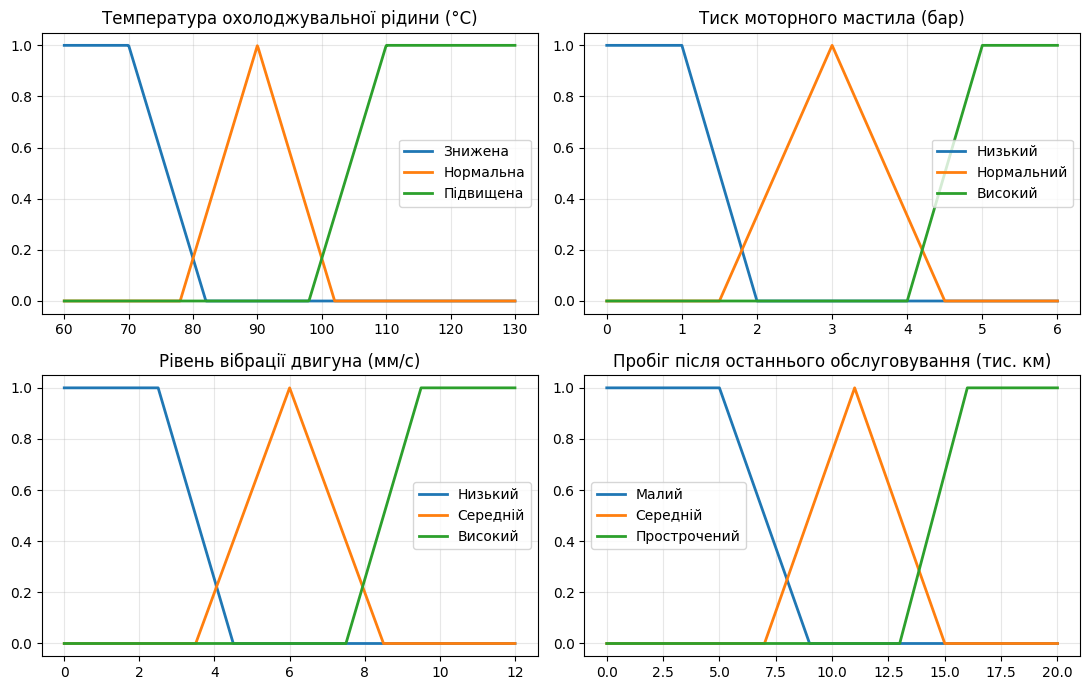

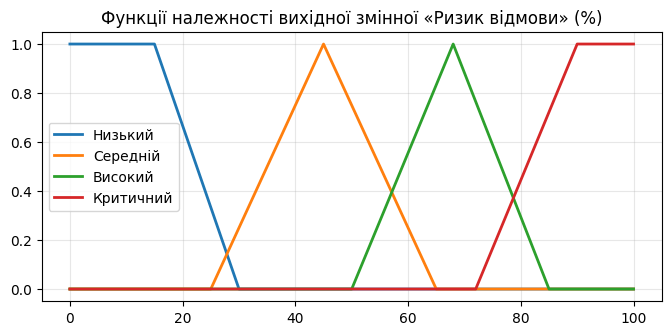

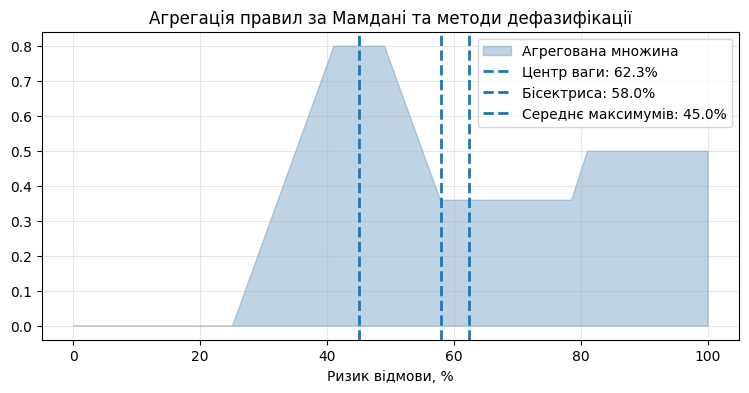

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import skfuzzy as fuzz
from diagnostics import fuzzy_engine as fe

# графік вхідних змінних
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (name, var) in zip(axes.flat, fe.INPUT_VARIABLES.items()):
    u = fe.UNIVERSES[name]
    for term, (title, _, _) in var['terms'].items():
        ax.plot(u, fe.INPUT_MFS[name][term], linewidth=2, label=title)
    ax.set_title(f"{var['label']} ({var['unit']})")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

# графік вихідної змінної
plt.figure(figsize=(8, 3.5))
for term, (title, _, _) in fe.RISK_TERMS.items():
    plt.plot(fe.RISK_UNIVERSE, fe.RISK_MFS[term], linewidth=2, label=title)
plt.title('Функції належності вихідної змінної «Ризик відмови» (%)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# порівняння методів дефазифікації для тестового прикладу
test_vals = {'temperature': 104, 'oil_pressure': 1.4, 'vibration': 6.0, 'service_km': 13.0}
deg = fe.fuzzify(test_vals)
strengths = fe.activate_rules(deg, 'min')
agg, _ = fe.mamdani_aggregate(strengths, 'min')

plt.figure(figsize=(9, 4))
plt.fill_between(fe.RISK_UNIVERSE, agg, alpha=0.35, color='steelblue', label='Агрегована множина')
for m, lbl in [('centroid', 'Центр ваги'), ('bisector', 'Бісектриса'), ('mom', 'Середнє максимумів')]:
    val = fuzz.defuzz(fe.RISK_UNIVERSE, agg, m)
    plt.axvline(val, linestyle='--', linewidth=2, label=f'{lbl}: {val:.1f}%')
plt.title('Агрегація правил за Мамдані та методи дефазифікації')
plt.xlabel('Ризик відмови, %')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [24]:
import subprocess, time
from google.colab import output

server = subprocess.Popen(['python', 'manage.py', 'runserver', '0.0.0.0:8000'])
time.sleep(2)
print("Натисніть на посилання нижче, щоб відкрити веб-застосунок:")
output.serve_kernel_port_as_window(8000)

Натисніть на посилання нижче, щоб відкрити веб-застосунок:
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [21]:
%%writefile diagnostics/views.py
import json
from django.http import JsonResponse
from django.shortcuts import redirect, render
from django.views.decorators.http import require_POST
from . import fuzzy_engine as fe
from .forms import DiagnosticForm
from .models import DiagnosticRecord

def _run(cleaned):
    values = {name: cleaned[name] for name in fe.INPUT_VARIABLES}
    return fe.diagnose(values, cleaned['algorithm'], cleaned['tnorm'], cleaned['defuzz'])

def index(request):
    if request.method == 'POST':
        form = DiagnosticForm(request.POST)
        if form.is_valid():
            data = form.cleaned_data
            if 'save_btn' in request.POST:
                result = _run(data)
                if result['covered']:
                    DiagnosticRecord.objects.create(
                        vehicle=data['vehicle'] or 'Без назви',
                        temperature=data['temperature'], oil_pressure=data['oil_pressure'],
                        vibration=data['vibration'], service_km=data['service_km'],
                        algorithm=data['algorithm'], risk=result['risk'],
                        level=result['level']['title']
                    )
                return redirect('diagnostics:history')
            result = _run(data)
        else:
            result = _run({
                'algorithm': 'mamdani', 'tnorm': 'min', 'defuzz': 'centroid',
                **{name: var['default'] for name, var in fe.INPUT_VARIABLES.items()}
            })
    else:
        form = DiagnosticForm()
        result = _run({
            'algorithm': 'mamdani', 'tnorm': 'min', 'defuzz': 'centroid',
            **{name: var['default'] for name, var in fe.INPUT_VARIABLES.items()}
        })

    variables = [
        {'field': form[name], 'unit': var['unit'], 'low': var['range'][0], 'high': var['range'][1]}
        for name, var in fe.INPUT_VARIABLES.items()
    ]
    return render(request, 'diagnostics/index.html', {
        'form': form, 'variables': variables, 'result': result
    })

@require_POST
def api_diagnose(request):
    try:
        payload = json.loads(request.body)
    except json.JSONDecodeError:
        return JsonResponse({'errors': {'__all__': ['Некоректний JSON']}}, status=400)
    form = DiagnosticForm(payload)
    if not form.is_valid():
        return JsonResponse({'errors': form.errors.get_json_data()}, status=400)
    return JsonResponse(_run(form.cleaned_data))

@require_POST
def save_record(request):
    return index(request)

def history(request):
    records = DiagnosticRecord.objects.all()[:20]
    return render(request, 'diagnostics/history.html', {'records': records})

Overwriting diagnostics/views.py


In [22]:
%%writefile diagnostics/templates/diagnostics/index.html
{% extends 'diagnostics/base.html' %}
{% block content %}
<div class="grid">
    <div class="card">
        <h3>Вхідні параметри та налаштування</h3>
        <form id="diag-form" method="post" action="{% url 'diagnostics:index' %}">
            {% csrf_token %}
            <div class="field">{{ form.vehicle.label_tag }}{{ form.vehicle }}</div>
            <div class="field">{{ form.algorithm.label_tag }}{{ form.algorithm }}</div>
            <div class="field">{{ form.tnorm.label_tag }}{{ form.tnorm }}</div>
            <div class="field">{{ form.defuzz.label_tag }}{{ form.defuzz }}</div>
            <hr>
            {% for v in variables %}
            <div class="field">
                {{ v.field.label_tag }}
                {{ v.field }}
                <input type="range" step="0.1" min="{{ v.low }}" max="{{ v.high }}" value="{{ v.field.value|stringformat:'s' }}" data-sync="{{ v.field.name }}">
            </div>
            {% endfor %}
            <div style="display: flex; gap: 10px;">
                <button type="submit" name="calc_btn" style="background: #0f766e;">Розрахувати ризик</button>
                <button type="submit" name="save_btn">Зберегти в журнал</button>
            </div>
        </form>
    </div>

    <div class="card">
        <h3>Результат нечіткого виводу</h3>
        <div id="risk-banner" class="risk-box {{ result.level.code }}">
            Ризик відмови: <span id="risk-val">{{ result.risk }}</span>% — <span id="risk-title">{{ result.level.title }}</span>
        </div>

        <h4>Спрацювали правила (пояснення висновку):</h4>
        <div id="fired-rules">
            {% for r in result.fired %}
            <div class="rule-item">
                <strong>[{{ r.code }}] (сила: {{ r.alpha }})</strong>: {{ r.text }}<br>
                <em>Причина:</em> {{ r.cause }}<br>
                <em>Рекомендація:</em> {{ r.advice }}
            </div>
            {% endfor %}
        </div>

        <h4>Порівняння алгоритмів та методів дефазифікації:</h4>
        <table>
            <thead><tr><th>Метод виводу</th><th>Ризик, %</th></tr></thead>
            <tbody id="comp-body">
                {% for c in result.comparison %}
                <tr><td>{{ c.title }}</td><td>{{ c.risk }}%</td></tr>
                {% endfor %}
            </tbody>
        </table>
    </div>
</div>

<script>
const form = document.getElementById('diag-form');
document.querySelectorAll('input[type="range"]').forEach(slider => {
    const numInput = form.querySelector(`[name="${slider.dataset.sync}"]`);
    slider.addEventListener('input', () => { numInput.value = slider.value; });
    numInput.addEventListener('input', () => { slider.value = numInput.value; });
});
</script>
{% endblock %}

Overwriting diagnostics/templates/diagnostics/index.html


In [23]:
with open('vehicle_diag/settings.py', 'r', encoding='utf-8') as f:
    code = f.read()

code = code.replace(
    "CSRF_TRUSTED_ORIGINS = ['https://*.colab.googleusercontent.com', 'https://*.google.com']",
    "CSRF_TRUSTED_ORIGINS = ['https://*.colab.dev', 'https://*.colab.googleusercontent.com', 'https://*.google.com']"
)

with open('vehicle_diag/settings.py', 'w', encoding='utf-8') as f:
    f.write(code)